In [25]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
import os

In [26]:
load_dotenv()

# Initialize the Gemini LLM instead of ChatOpenAI
model = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash", # Or gemini-2.5-pro, gemini-3.5-flash, etc.
    temperature=0,
    api_key=os.getenv("API_KEY")
)

In [27]:
#creating state class for managing state for graph
class LLMState(TypedDict):
    question: str
    response: str 

In [28]:
def llm_qs(state: LLMState) -> LLMState:
    # extracting question from state
    question = state.get("question", "")
    #creating prompt for LLM
    prompt = f"Answer the following question: {question}"
    # ask question to LLM
    response = model.invoke(prompt).text #content carries the response from LLM
    #update answer in state
    state["response"] = response
    return state

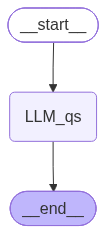

In [31]:
graph = StateGraph(LLMState)

#creating nodes
graph.add_node("LLM_qs",llm_qs)
#Creating edges
graph.add_edge(START, "LLM_qs")
graph.add_edge("LLM_qs", END)

#compiling the graph
workflow =graph.compile()

workflow

In [30]:
#running the graph with a sample question
initial_state = {"question": "What is the capital of France?"}
final_output = workflow.invoke(initial_state)
print(final_output)

d:\Tutorials\SimpleChatBot\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


{'question': 'What is the capital of France?', 'response': 'The capital of France is **Paris**.'}
